#  Sesioni 8 — Projekti Final: Parashikimi i Anulimeve të Hotelit

### Projekti i fundit: Aplikojmë të gjithë procesin e ML në një problem real biznesi

---

##  Çfarë do të bëjmë sot?

Sot lidhim **gjithçka** që kemi mësuar në 7 sesionet e mëparshme në një projekt të plotë.

| Hapi | Aktiviteti | Nga cili sesion? |
|------|------------|------------------|
| 1 | Kuptojmë **problemin e biznesit** | Mendimi i data scientist |
| 2 | Ngarkojmë & eksplorojmë të dhënat (**EDA**) | Sesioni 1–2 |
| 3 | Trajtojmë **vlerat e munguara** | Pastrimi i të dhënave |
| 4 | Vizualizojmë lidhjet kryesore | Matplotlib |
| 5 | **Kodojmë & ndajmë** të dhënat | `get_dummies` + `train_test_split` |
| 6 | Trajnojmë **3 modele** | Sesioni 3–5 |
| 7 | Krahasojmë me **accuracy, precision, recall, F1** | Sesioni 4–5 |
| 8 | **Interpretim biznesi** — kostoja e gabimeve | Sot (e re!) |
| 9 | **Ushtrime + Sfida finale** | Gjithçka |


---

#  Problemi i biznesit

## Skenari

Je **data scientist** në një zinxhir të madh hoteli. Çdo vit hoteli humbet shumë të ardhura nga anulimet e fundit. Dhomat e rezervuara mbeten bosh dhe nuk mund të rishiten në momentin e fundit.

**Menaxheri i të ardhurave** pyet:

> *«Kur vjen një rezervim i ri, a mund ta parashikojmë nëse do të anulohet — para se të ndodhë?»*

Nëse po, mund të:
-  **Kontaktojmë mysafirët me risk të lartë** për të konfirmuar rezervimin herët
-  **Rregullojmë politikën e overbooking** në mënyrë më të zgjuar
-  **Dërgojmë oferta** (zbritje, upgrade) për të shmangur anulimin

## Ndryshuesi i synuar (target)

```
is_cancelled = 1  →  Mysafiri e anuloi rezervimin
is_cancelled = 0  →  Mysafiri erdhi dhe qëndroi
```

Ky është një problem **klasifikimi binar** (Session 3 — Logistic Regression).

##  Pse ka rëndësi ky problem?

| Anulimi NUK u parashikua | Anulimi u parashikua GABIMISHT |
|--------------------------|--------------------------------|
| Dhoma boshe, humbje të ardhurash | Kohë e humbur duke telefonuar një mysafir të mirë |
| Mundësi e humbur për rishitje | Pak shqetësim për mysafirin |
| **KOSTO E LARTË** | **KOSTO E ULËT** |

Ky është rasti klasik ku na intereson më shumë **Recall** (të kapim anulimet) se sa **Precision**.

---

#  Përshkrimi i dataset-it

Dataset: `hotel_booking_cancellations.csv` — **~5,000 rezervime**, **24 kolona**.

### Informacioni i rezervimit
| Feature | Tipi | Përshkrimi |
|---------|------|------------|
| `booking_id` | ID | Identifikues unik |
| `hotel_type` | kategorik | *City Hotel* ose *Resort Hotel* |
| `lead_time` | numerik | Ditë midis rezervimit dhe mbërritjes |
| `arrival_month` | numerik (1–12) | Muaji i mbërritjes |
| `arrival_week_number` | numerik (1–52) | Java e vitit |
| `arrival_day` | numerik (1–31) | Dita e mbërritjes |
| `stay_duration` | numerik | Total netësh = weekend + weekday |
| `weekend_nights` | numerik | Netë Shtunë/Diele |
| `weekday_nights` | numerik | Netë Hënë–Premte |

### Informacioni i klientit
| Feature | Tipi | Përshkrimi |
|---------|------|------------|
| `adults` / `children` / `babies` | numerik | Numri i secilit |
| `customer_type` | kategorik | *Transient*, *Transient-Party*, *Contract*, *Group* |
| `repeated_guest` | binar | 1 nëse ka qëndruar më parë |

### Sjellja e rezervimit
| Feature | Tipi | Përshkrimi |
|---------|------|------------|
| `previous_cancellations` | numerik | Anulime të kaluara |
| `previous_bookings` | numerik | Rezervime të përfunduara më parë |
| `booking_changes` | numerik | Sa herë u ndryshua rezervimi |
| `deposit_type` | kategorik | *No Deposit*, *Non Refund*, *Refundable* |

### Financiare + tregu
| Feature | Tipi | Përshkrimi |
|---------|------|------------|
| `average_daily_rate` | numerik | Çmimi për natë (€) |
| `required_car_parking_spaces` | numerik | Vende parkimi |
| `special_requests` | numerik | Numri i kërkesave speciale |
| `market_segment` | kategorik | *Online*, *Offline*, *Corporate*, *Direct* |
| `distribution_channel` | kategorik | Kanali i rezervimit |

###  Target
| `is_cancelled` | binar | **1 = anular**, 0 = i përfunduar |

---

##  Hipotezat tona (domain reasoning)

Para se të ekzekutojmë ndonjë model, formojmë hipoteza!

| Feature | Efekti i pritur | Pse? |
|---------|-----------------|------|
| `lead_time` i gjatë | ↑ anulime | Më shumë kohë për të ndryshuar planet |
| `previous_cancellations` | ↑ anulime | Sjellja e kaluar parashikon të ardhmen |
| `deposit_type = Non Refund` | ↓ anulime | Nuk duan të humbasin paratë |
| `special_requests` | ↓ anulime | Mysafirë të angazhuar → më të përkushtuar |
| `repeated_guest` | ↓ anulime | Klientët e besueshëm anulojnë rrallë |
| `hotel_type = City Hotel` | ↑ anulime | Udhëtimet e biznesit anulohen më shpesh |

### Ushtrim i shpejtë (shkruaj këtu)

Plotëso me fjalët e tua (nuk ka përgjigje të gabuar):

> Unë mendoj se feature-i më i rëndësishëm është **____________** 


---

#  Setup — libraritë

In [1]:
# Libraritë bazë
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modelet dhe metrikat (Sesionet 3–6)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)


---

#  Ngarko të dhënat & shiko fillimisht

In [2]:
df = pd.read_csv('../data/hotel_booking_cancellations.csv')

print(f'Forma e dataset-it: {df.shape[0]:,} rreshta × {df.shape[1]} kolona')
df.head()


Forma e dataset-it: 5,000 rreshta × 24 kolona


,booking_id,hotel_type,lead_time,arrival_month,arrival_week_number,arrival_day,stay_duration,weekend_nights,weekday_nights,adults,...,previous_cancellations,previous_bookings,booking_changes,deposit_type,average_daily_rate,required_car_parking_spaces,special_requests,market_segment,distribution_channel,is_cancelled
0,100001,City Hotel,52,10,7,10,2,0,2,1,...,0,7,0,No Deposit,NaN,0,1.0,Offline,TA/TO,0
1,100002,Resort Hotel,6,9,9,12,4,0,4,2,...,2,0,0,No Deposit,111.32,0,0.0,Corporate,Corporate,1
2,100003,Resort Hotel,121,7,36,20,1,0,0,4,...,0,0,0,Non Refund,154.70,0,0.0,Corporate,Corporate,0
3,100004,City Hotel,113,5,23,13,1,0,0,2,...,0,2,0,No Deposit,122.34,0,0.0,Corporate,Corporate,1
4,100005,City Hotel,119,2,24,21,5,1,4,2,...,0,0,0,No Deposit,174.17,0,1.0,Online,TA/TO,0


In [3]:
# Çfarë tipesh kemi? Ka vlera të munguara?
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   booking_id                   5000 non-null   int64  
 1   hotel_type                   5000 non-null   str    
 2   lead_time                    5000 non-null   int64  
 3   arrival_month                5000 non-null   int64  
 4   arrival_week_number          5000 non-null   int64  
 5   arrival_day                  5000 non-null   int64  
 6   stay_duration                5000 non-null   int64  
 7   weekend_nights               5000 non-null   int64  
 8   weekday_nights               5000 non-null   int64  
 9   adults                       5000 non-null   int64  
 10  children                     4925 non-null   float64
 11  babies                       5000 non-null   int64  
 12  customer_type                5000 non-null   str    
 13  repeated_guest               

In [4]:
# Përmbledhje numerike — shiko min, max, mean
df.describe().round(2)


,booking_id,lead_time,arrival_month,arrival_week_number,arrival_day,stay_duration,weekend_nights,weekday_nights,adults,children,babies,repeated_guest,previous_cancellations,previous_bookings,booking_changes,average_daily_rate,required_car_parking_spaces,special_requests,is_cancelled
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,4925.00,5000.00,5000.00,5000.00,5000.00,5000.00,4900.00,5000.00,4975.00,5000.00
mean,102500.50,98.32,6.46,26.20,16.19,3.58,1.18,2.36,2.03,0.32,0.04,0.07,0.30,0.60,0.35,125.53,0.06,0.75,0.39
std,1443.52,65.16,3.48,14.78,8.91,1.93,0.99,1.70,0.66,0.66,0.21,0.26,1.04,1.77,0.82,35.88,0.26,1.01,0.49
min,100001.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,20.00,0.00,0.00,0.00
25%,101250.75,51.00,3.00,14.00,9.00,2.00,0.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,101.12,0.00,0.00,0.00
50%,102500.50,83.00,6.00,26.00,16.00,3.00,1.00,2.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,125.50,0.00,0.00,0.00
75%,103750.25,132.00,10.00,39.00,24.00,5.00,2.00,3.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,149.34,0.00,1.00,1.00
max,105000.00,500.00,12.00,52.00,31.00,11.00,4.00,7.00,4.00,3.00,2.00,1.00,10.00,11.00,5.00,250.20,2.00,5.00,1.00


###  Shiko output-in e `describe()`:

1. Cili është **max** i `lead_time`? A duket i arsyeshëm? (p.sh. 500 ditë = ~2 vite përpara)
2. A ka features me **shkallë shumë të ndryshme**? (p.sh. `lead_time` vs `babies`) — pse ka rëndësi për Logistic Regression?
3. A ka vlera të dyshimta? (p.sh. `previous_cancellations` shumë i lartë)


---

#  Vlerat e munguara (Missing Values)



In [5]:
# Sa vlera mungojnë për çdo kolonë?
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)

# Mbaj vetëm kolonat që kanë mungesa
missing_report = pd.DataFrame({
    'mungesa': missing[missing > 0],
    'përqindja': missing_pct[missing > 0]
}).sort_values('mungesa', ascending=False)

print(f'Totali i vlerave të munguara: {missing.sum()}\n')
print(missing_report if len(missing_report) > 0 else 'Nuk ka vlera të munguara!')


Totali i vlerave të munguara: 240

                    mungesa  përqindja
average_daily_rate      100        2.0
children                 75        1.5
market_segment           40        0.8
special_requests         25        0.5


### Strategjia për vlerat e munguara

Të gjitha kolonat kanë **më pak se 3%** mungesa — e sigurt të mbushim me vlera të arsyeshme.

| Kolona | Strategjia | Pse? |
|--------|------------|------|
| `children` | Mbush me **0** | Nëse nuk është shkruar → ndoshta 0 fëmijë |
| `average_daily_rate` | Mbush me **medianën** | Më e qëndrueshme se mesatarja ndaj outliers |
| `special_requests` | Mbush me **0** | Nëse nuk është shkruar → 0 kërkesa |
| `market_segment` | Mbush me **modën** (më e shpeshta) | Zgjedhje e arsyeshme default |

**Rregulli i artë:** Mos fshi rreshta në dataset të vogël pa arsye të fortë.


In [6]:
# Mbush vlerat e munguara (imputation)
df['children'] = df['children'].fillna(0)
df['average_daily_rate'] = df['average_daily_rate'].fillna(df['average_daily_rate'].median())
df['special_requests'] = df['special_requests'].fillna(0)
df['market_segment'] = df['market_segment'].fillna(df['market_segment'].mode()[0])

# Verifiko — duhet të jetë 0
print(f'Vlera të munguara pas pastrimit: {df.isna().sum().sum()}')

Vlera të munguara pas pastrimit: 0


---

# Shpërndarja e target-it

Sa anulime kemi? Kjo ndikon në zgjedhjen e metrikës.


Shpërndarja e klasave:
   0 (Not Cancelled): 3,068  (61.4%)
   1 (Cancelled): 1,932  (38.6%)


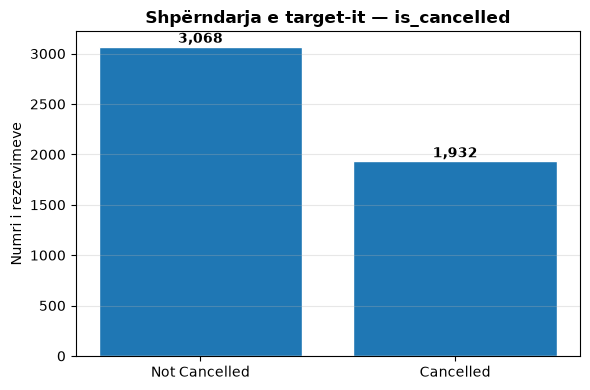

In [7]:
# Numëro klasat
counts = df['is_cancelled'].value_counts()
pct = df['is_cancelled'].value_counts(normalize=True) * 100

print('Shpërndarja e klasave:')
for label, name in [(0, 'Not Cancelled'), (1, 'Cancelled')]:
    print(f'   {label} ({name}): {counts[label]:>4,d}  ({pct[label]:.1f}%)')

# Grafik i thjeshtë
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Not Cancelled', 'Cancelled'], counts.values, edgecolor='white')
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f'{v:,}', ha='center', fontweight='bold')
ax.set_ylabel('Numri i rezervimeve')
ax.set_title('Shpërndarja e target-it — is_cancelled', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


###  Interpretimi

Balanca e klasave është rreth **60/40** — disbalancë e moderuar.

- **Accuracy** ende ka kuptim (nuk jemi në situatën 99/1)
- Duhet të përdorim **`stratify=y`** te `train_test_split` (Sesioni 4–5)
- **F1-score** është metrikë e mirë kryesore sepse na interesojnë të dyja klasat



---

# Testojmë hipotezat tona



In [8]:
# Norma e anulimit sipas një kolone kategorike
def cancel_rate_by(col):
    """Kthen normën e anulimit të grupuar sipas një kolone."""
    return (
        df.groupby(col)['is_cancelled']
          .agg(['mean', 'count'])
          .rename(columns={'mean': 'cancel_rate'})
          .round(3)
          .sort_values('cancel_rate', ascending=False)
    )

print(' Sipas hotel_type:')
print(cancel_rate_by('hotel_type'))
print('\nSipas deposit_type:')
print(cancel_rate_by('deposit_type'))
print('\nSipas repeated_guest:')
print(cancel_rate_by('repeated_guest'))
print('\n Sipas market_segment:')
print(cancel_rate_by('market_segment'))


 Sipas hotel_type:
              cancel_rate  count
hotel_type                      
City Hotel          0.408   3101
Resort Hotel        0.352   1899

Sipas deposit_type:
              cancel_rate  count
deposit_type                    
No Deposit          0.428   4331
Refundable          0.337     86
Non Refund          0.082    583

Sipas repeated_guest:
                cancel_rate  count
repeated_guest                    
0                     0.408   4627
1                     0.113    373

 Sipas market_segment:
                cancel_rate  count
market_segment                    
Corporate             0.395    663
Online                0.389   2907
Direct                0.386    443
Offline               0.372    987


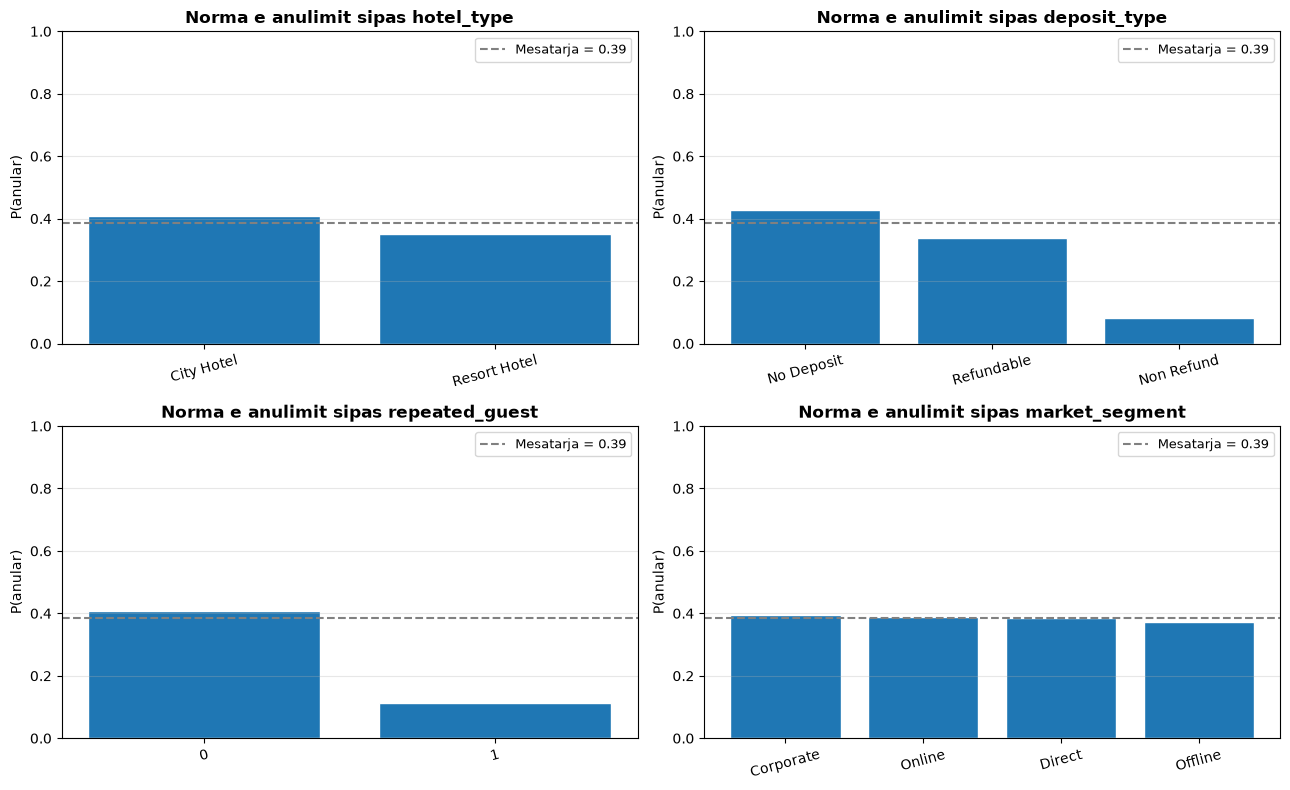

In [9]:
# Vizualizo 4 ndarjet më të rëndësishme
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
overall = df['is_cancelled'].mean()

for ax, col in zip(axes.flatten(),
                    ['hotel_type', 'deposit_type', 'repeated_guest', 'market_segment']):
    rates = df.groupby(col)['is_cancelled'].mean().sort_values(ascending=False)
    ax.bar(rates.index.astype(str), rates.values, edgecolor='white')
    ax.axhline(overall, color='gray', linestyle='--',
               label=f'Mesatarja = {overall:.2f}')
    ax.set_title(f'Norma e anulimit sipas {col}', fontweight='bold')
    ax.set_ylabel('P(anular)')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


---

#  Përgatit të dhënat për ML



In [10]:
# Ndaj features nga target dhe hiq ID-në
X = df.drop(columns=['is_cancelled', 'booking_id'])
y = df['is_cancelled']

print(f'Forma e features: {X.shape}')
print(f'Forma e target:   {y.shape}')
print('\nKolona kategorike që duhen koduar:')
print(list(X.select_dtypes(exclude='number').columns))


Forma e features: (5000, 22)
Forma e target:   (5000,)

Kolona kategorike që duhen koduar:
['hotel_type', 'customer_type', 'deposit_type', 'market_segment', 'distribution_channel']


In [11]:
# One-Hot Encoding për kolonat kategorike
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print(f'Para encoding: {X.shape[1]} kolona')
print(f'Pas encoding:  {X_encoded.shape[1]} kolona')
print('\nShembull i kolonave të reja:')
new_cols = [c for c in X_encoded.columns if c not in X.columns]
print(new_cols[:8], '...')


Para encoding: 22 kolona
Pas encoding:  29 kolona

Shembull i kolonave të reja:
['hotel_type_Resort Hotel', 'customer_type_Group', 'customer_type_Transient', 'customer_type_Transient-Party', 'deposit_type_Non Refund', 'deposit_type_Refundable', 'market_segment_Direct', 'market_segment_Offline'] ...


In [12]:
# Ndarja train/test — stratify=y ruan balancën e klasave
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f'Train: {X_train.shape[0]:,} rreshta  ({y_train.mean() * 100:.1f}% të anulara)')
print(f'Test:  {X_test.shape[0]:,} rreshta  ({y_test.mean() * 100:.1f}% të anulara)')
print('\n Balanca e klasave u ruajt falë stratify=y')


Train: 4,000 rreshta  (38.6% të anulara)
Test:  1,000 rreshta  (38.6% të anulara)

 Balanca e klasave u ruajt falë stratify=y


---

# Trajnojmë 3 modele

Do të trajnojmë:

1.  **Logistic Regression** — baseline (gjithmonë fillojmë këtu) · Sesioni 3
2.  **Decision Tree** — i thjeshtë, i interpretueshëm · Sesioni 5
3.  **Random Forest** — ensemble i pemëve, zakonisht më i forti · Sesioni 5

> **Shënim:** Logistic Regression përfiton nga **scaling** → e vendosim në `Pipeline` me `StandardScaler`.
> Modelet me pemë **nuk** kanë nevojë për scaling.


In [13]:
# Përcakto 3 modelet
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
}

# Trajno secilin dhe ruaj parashikimet
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f'✓ {name} u trajnua')


✓ Logistic Regression u trajnua
✓ Decision Tree u trajnua
✓ Random Forest u trajnua


---

#  Krahasimi i modeleve

>  **Rikujtesë Sesioni 4:** Accuracy, Precision, Recall, F1 — secila tregon diçka tjetër!


In [14]:
# Ndërto tabelën e metrikave
rows = []
for name, y_pred in predictions.items():
    rows.append({
        'Modeli':    name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
    })

comparison = pd.DataFrame(rows).round(3)
comparison = comparison.sort_values('F1', ascending=False).reset_index(drop=True)
comparison


,Modeli,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.753,0.719,0.591,0.649
1,Random Forest,0.742,0.718,0.547,0.621
2,Decision Tree,0.721,0.685,0.513,0.587


In [15]:
# Raport i detajuar për modelin fitues
winner_name = comparison.iloc[0]['Modeli']
print(f' Classification report — {winner_name}\n')
print(classification_report(
    y_test, predictions[winner_name],
    target_names=['Përfunduar (0)', 'Anular (1)']
))


 Classification report — Logistic Regression



                precision    recall  f1-score   support

Përfunduar (0)       0.77      0.86      0.81       614
    Anular (1)       0.72      0.59      0.65       386

      accuracy                           0.75      1000
     macro avg       0.74      0.72      0.73      1000
  weighted avg       0.75      0.75      0.75      1000



In [16]:
# Vlerëso ndikimin e biznesit të modelit fitues në test set
cm = confusion_matrix(y_test, predictions[winner_name])
tn, fp, fn, tp = cm.ravel()

cost_fn = 200   # € — e ardhura mesatare e humbur për anulim të humbur
cost_fp = 8     # € — kostoja mesatare e një telefonate konfirmimi
total_cost = fn * cost_fn + fp * cost_fp

# Baseline: çfarë nëse nuk bëjmë asgjë (kurrë nuk parashikojmë anulime)?
baseline_cost = int(y_test.sum()) * cost_fn

print(f' Ndikimi në biznes — {len(y_test):,} rezervime test — modeli: {winner_name}\n')
print(f'  Anulime të kapura saktë (TP):     {tp:>4d}')
print(f'  Anulime të humbura (FN):          {fn:>4d}   × €{cost_fn} = €{fn * cost_fn:,.0f}')
print(f'  Alarme të gabuara (FP):           {fp:>4d}   × €{cost_fp}   = €{fp * cost_fp:,.0f}')
print(f'  ─────────────────────────────────────────────────────────────')
print(f'  Kosto totale ME model:                     €{total_cost:>7,.0f}')
print(f'  Kosto PA model (bëjmë asgjë):              €{baseline_cost:>7,.0f}')
print(f'  Kursime të vlerësuara në test set:         €{baseline_cost - total_cost:>7,.0f}')


 Ndikimi në biznes — 1,000 rezervime test — modeli: Logistic Regression

  Anulime të kapura saktë (TP):      228
  Anulime të humbura (FN):           158   × €200 = €31,600
  Alarme të gabuara (FP):             89   × €8   = €712
  ─────────────────────────────────────────────────────────────
  Kosto totale ME model:                     € 32,312
  Kosto PA model (bëjmë asgjë):              € 77,200
  Kursime të vlerësuara në test set:         € 44,888


###  Mesazhi kryesor

*«modeli ynë ka 75% accuracy»* do të thotë pak për Menaxherin e të ardhurave.  
*«modeli ynë kap rreth 6 nga 10 anulime dhe do të kishte kursyer ~€45,000 në këto 1,000 rezervime»* — **kjo është deliverable e një data scientist**.


---

## Ushtrimi 1 — Ndrysho madhësinë e test set 

Default ishte `test_size=0.20`. Ritrajno **Logistic Regression** me:

- `test_size = 0.10`
- `test_size = 0.30`
- `test_size = 0.40`

Për secilin, printo **F1-score**. Cili split jep F1 më të lartë? Çfarë mund të jetë mashtruese në këtë krahasim?


---

## Ushtrimi 2 — Random Forest: sa pemë? 

Trajno `RandomForestClassifier` me `n_estimators` në `[10, 50, 100, 200, 300]` dhe regjistro test F1.  
A ia vlen 300 pemë krahasuar me 100?


---

## Ushtrimi 3 — Feature importance 

Duke përdorur **Random Forest** të trajnuar, mer top 10 features më të rëndësishme  
(`rf.feature_importances_`) dhe vizatoji si horizontal bar chart.



---

#  Mini-Projekt 

**Misioni yt:** ndërto modelin **më të mirë** të parashikimit të anulimeve që mundesh!

### Rregullat

1. Përdor të njëjtin dataset (`hotel_booking_cancellations.csv`).
2. Mund të përdorësh çdo model që kemi mësuar (Logistic, Tree, Random Forest, KNN).
3. **Duhet** të përdorësh **cross-validation** për të zgjedhur modelin — jo një `random_state` me fat!
4. **Duhet** të zgjedhësh metrikë të përshtatshme për biznesin (mendo FN vs FP).
5. Prezanto rezultatin si histori e shkurtër.


In [17]:

models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),
    
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ])
}

In [18]:
results = []

for name, model in models.items():
    cv_f1 = cross_val_score(
        model,
        X_encoded,
        y,
        cv=5,
        scoring='f1',
        n_jobs=-1
    )

    cv_recall = cross_val_score(
        model,
        X_encoded,
        y,
        cv=5,
        scoring='recall',
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'F1 mean': cv_f1.mean(),
        'F1 std': cv_f1.std(),
        'Recall mean': cv_recall.mean(),
        'Recall std': cv_recall.std()
    })

comparison = pd.DataFrame(results)

print(comparison.round(3))

                 Model  F1 mean  F1 std  Recall mean  Recall std
0  Logistic Regression    0.627   0.014        0.549       0.007
1        Decision Tree    0.584   0.023        0.533       0.038
2        Random Forest    0.597   0.023        0.498       0.019
3                  KNN    0.518   0.016        0.473       0.016
